In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

from scipy.spatial.distance import cdist, pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree, connected_components


In [4]:
iris = load_iris()

In [5]:
X = iris.data
y = iris.target

In [8]:
%%time
distance = euclidean_distances(X)
mst = minimum_spanning_tree(distance)  

CPU times: user 8.63 ms, sys: 35 μs, total: 8.67 ms
Wall time: 7.63 ms


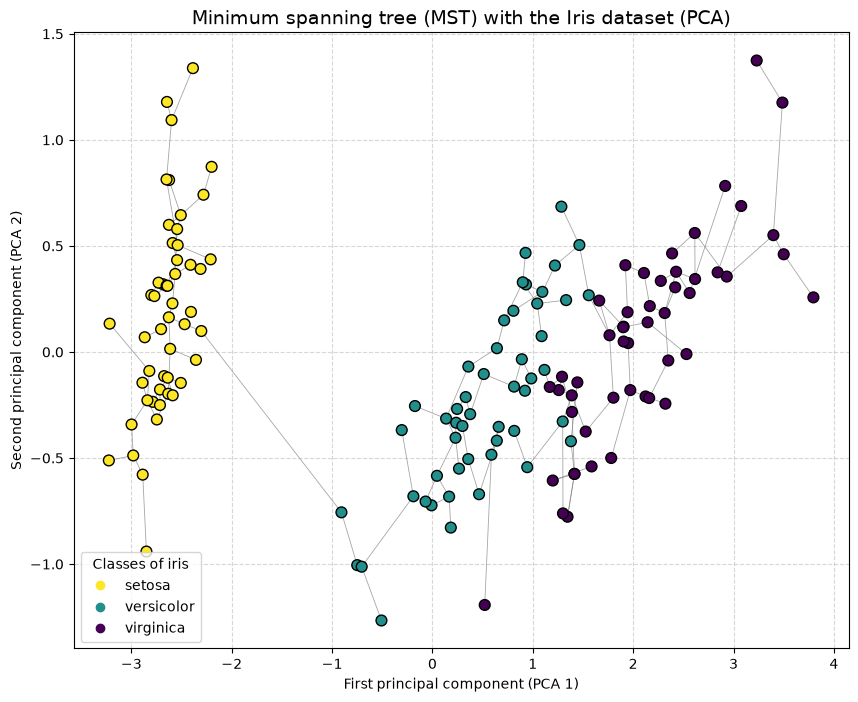

In [9]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

plt.figure(figsize=(10, 8))

rows, cols = mst.nonzero()

for i, j in zip(rows, cols):
  plt.plot(
      [X_2d[i, 0], X_2d[j, 0]],
      [X_2d[i, 1], X_2d[j, 1]],
      color='gray',
      linestyle='-',
      linewidth=0.6,
      alpha=0.7,
  )

scatter = plt.scatter(
    X_2d[:, 0], X_2d[:, 1], c=y, cmap='viridis_r', s=60, edgecolor='k', zorder=3
)
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=list(iris.target_names),
    title="Classes of iris",
)

plt.title(
    "Minimum spanning tree (MST) with the Iris dataset (PCA)", fontsize=14
)
plt.xlabel("First principal component (PCA 1)")
plt.ylabel("Second principal component (PCA 2)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()